<a href="https://colab.research.google.com/github/vandita1803/DAA-Lab/blob/main/MinimumWindowSubstring.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import time
import statistics
from collections import Counter

def min_window(s, t):
    if not s or not t or len(t) > len(s):
        return ""

    required = Counter(t)
    window = {}
    formed = 0
    required_unique = len(required)

    left = 0
    min_len = float("inf")
    min_start = 0

    for right, char in enumerate(s):
        window[char] = window.get(char, 0) + 1

        if char in required and window[char] == required[char]:
            formed += 1

        while formed == required_unique:
            if right - left + 1 < min_len:
                min_len = right - left + 1
                min_start = left

            left_char = s[left]
            window[left_char] -= 1

            if (left_char in required and
                    window[left_char] < required[left_char]):
                formed -= 1

            left += 1

    if min_len == float("inf"):
        return ""

    return s[min_start:min_start + min_len]


sizes = list(range(100, 10001, 500))
times = []
runs = 5

pattern = "ABC"

for n in sizes:
    # Fixed deterministic string with all required characters present
    base = "ADOBECODEBANCXYZ"
    s = (base * ((n // len(base)) + 1))[:n]

    measurements = []

    for _ in range(runs):
        start = time.perf_counter_ns()
        min_window(s, pattern)
        end = time.perf_counter_ns()

        measurements.append(end - start)

    times.append(statistics.median(measurements))


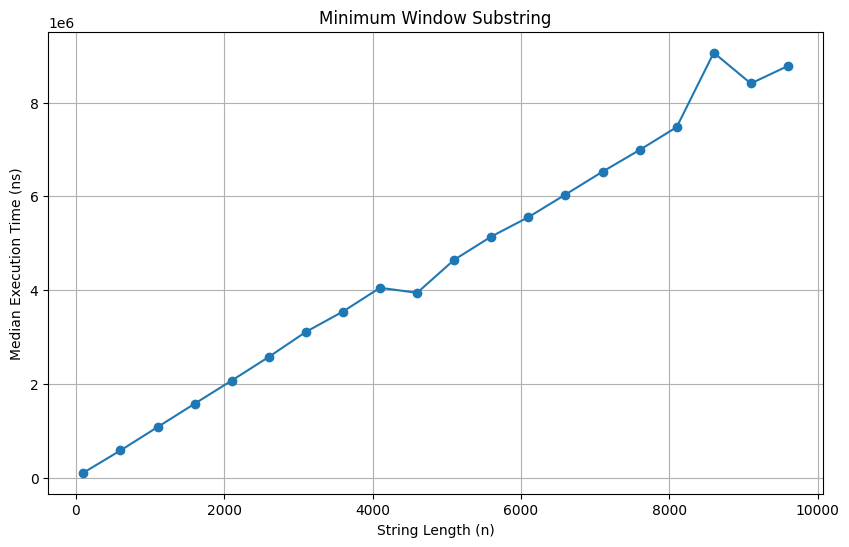

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.plot(sizes, times, marker='o')
plt.title("Minimum Window Substring")
plt.xlabel("String Length (n)")
plt.ylabel("Median Execution Time (ns)")
plt.grid(True)
plt.show()
